# Local Navigation

**Why use a state machine and not a potential field?**

A COMPLETER

### Test 1: Avoiding obstacles only

First, I program the Thymio to go forward at a constant speed of speed0=100. I then place an obstacle (Thymio's box) on the way, he must detect it, slow down and avoid it.
Here, I only test the sensors, the gains and its avoiding attitude, I don't need to know its position for now.

In [1]:
!pip install --upgrade tdmclient


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Connect your Thymio, open Thymio Suite and then execute:
import tdmclient.notebook
await tdmclient.notebook.start()

In [2]:
%%run_python 
#indicates that the following cell is sent to the Thymio

speed0 = 100       # nominal speed when going forward
obstThrL = 10      # low obstacle threshold to switch state 1->0
obstThrH = 20      # high obstacle threshold to switch state 0->1
obstSpeedGain = 5  # /100 (actual gain: 5/100=0.05)

state = 1          # 0=forward, 1=obstacle avoidance
obst = [0,0]       # measurements from left and right prox sensors

timer_period[0] = 10   # 10ms sampling time, frequency of 100 Hz, proximity sensors are actualized at a frequency of 10 Hz


@onevent # indicates to the Thymio that the function must be executed when a particular event happens, here its timer0, so the event is triggered every 10ms
def timer0():
    global prox_horizontal, motor_left_target, motor_right_target, state, obst, obstThrH, obstThrL, obstSpeedGain, speed0 

    # acquisition from the proximity sensors to detect obstacles
    obst = [prox_horizontal[0], prox_horizontal[4]] #Le programme prend seulement deux des capteurs horizontaux, le plus à gauche 0 et le plus à droite 4
    
    # tdmclient does not support yet multiple and/or in if statements:
    if state == 0: #Si en mode "suivre gradient"
        # switch from going forward to obst avoidance if obstacle detected
        if (obst[0] > obstThrH):
            state = 1
        elif (obst[1] > obstThrH):
            state = 1
    elif state == 1:
        if obst[0] < obstThrL:
            if obst[1] < obstThrL : 
                # switch from obst avoidance to going forward if obstacle got unseen
                state = 0
    if  state == 0 :
        # going forward
        motor_left_target = speed0
        motor_right_target = speed0
    else:
        # obstacle avoidance: accelerate wheel near obstacle
        motor_left_target = speed0 + obstSpeedGain * (obst[0] // 100) #On fait // 100 parce que la valeur brute des capteurs est très élevée (de 0 à 5000 environ)
        motor_right_target = speed0 + obstSpeedGain * (obst[1] // 100) # // est une division entière, donc on ne garde pas la partie décimale

In [3]:
stop()

The previous code is using only the two proximity sensors on the sides. So I'm changing this so that all proximity sensors are used, otherwise, obstacles in front might not get detected.

Also, the thresholds:

obstThrL = 10      # low obstacle threshold to switch state 1->0

obstThrH = 20      # high obstacle threshold to switch state 0->1

should be changed so that they correspond to the distance where we think we should stop/start avoiding the obstacle

In [4]:
%%run_python
#indicates that the following cell is sent to the Thymio

speed0 = 100       # nominal speed when going forward
obstThrL = 10      # low obstacle threshold to switch state 1->0
obstThrH = 20      # high obstacle threshold to switch state 0->1
obstSpeedGain = [6, 4, -2, -6, -8]    # /100
                  # gains used with front proximity sensors 0..4

state = 1          # 0=forward, 1=obstacle avoidance

timer_period[0] = 10   # 10ms sampling time, frequency of 100 Hz, proximity sensors are actualized at a frequency of 10 Hz


@onevent # indicates to the Thymio that the function must be executed when a particular event happens, here its timer0, so the event is triggered every 10ms
def timer0():
    global prox_horizontal, motor_left_target, motor_right_target, state, obstThrH, obstThrL, obstSpeedGain, speed0     
    
    # tdmclient does not support yet multiple and/or in if statements:
    if state == 0:
        for i in range(5):
            if prox_horizontal[i] > obstThrH: #if any of the proximity sensors detect an obstacle
                state = 1                     #we switch to obstacle avoidance mode
    elif state == 1:
        obstacle_gone = 1

        for i in range(5):
            if prox_horizontal[i] >= obstThrL: #if one of the 5 sensors still detects an obstacle
                obstacle_gone = 0              #then we stay in obstacle avoidance mode

        if obstacle_gone == 1:                 #if none of the sensors detect an obstacle
            state = 0                          #we switch to going forward mode
                
    if  state == 0 :
        # goal tracking: turn toward the goal
        spLeft = speed0
        spRight = speed0

        motor_left_target = spLeft
        motor_right_target = spRight

    else:
        # obstacle avoidance
        spLeft = speed0
        spRight = speed0

        for i in range(5):
            spLeft += prox_horizontal[i] * obstSpeedGain[i] // 100
            spRight += prox_horizontal[i] * obstSpeedGain[4 - i] // 100

        # motor control
        motor_left_target = spLeft
        motor_right_target = spRight

In [5]:
stop()

| Sensor | Left wheel gain | Right wheel gain |
|---|---:|---:|
| 0 — Far left | +6 | -8 |
| 1 — Left | +4 | -6 |
| 2 — Center | -2 | -2 |
| 3 — Right | -6 | +4 |
| 4 — Far right | -8 | +6 |

The asymetrical gains are so that the robot slows down while turning to avoid the obstacle.

The way of putting thresholds for the changing of the states:

obstThrL = 10      # low obstacle threshold to switch state 1->0

obstThrH = 20      # high obstacle threshold to switch state 0->1

is called an hysteresis, it's to avoid the states to change when the values of the proximity sensors fluctuate.

(Justify the threshold values later. For an obstacle at a distance of 12 cm, the value of the proximity sensor is around 2000, as seen in the Exercice 4 Jupyter Notebook. So for the threshold values, I should put:
obstThrL = 1000      # low obstacle threshold to switch state 1->0

obstThrH = 2000      # high obstacle threshold to switch state 0->1)

This code works great for convex obstacles but not for concave obstacles. For example, if you put an obstacle with a V shape in front of the robot, its left sensors will tell the robot to turn right, but the right sensors will also detect an obstacle so they will tell the robot to turn left hence the robot will be blocked.

To solve this problem, maybe we could implement a third state where when the robot detects that it is blocked, it makes an avoiding maneuver. Since the professor told us that we can put whatever shape of obstacle and wherever we want on the map, for now I leave this problem on the side and I will maybe solve it later.

### Test 2: Visual Localization and Waypoint Navigation

**Step 1: Computer Vision Integration**

First, I took Jan's code for computer vision.

Thymio position: (519.197998046875, 467.6744689941406, -0.593900203704834)
Goal position: (1074.4989013671875, 623.3563842773438, -1.7695555686950684)
Detected ArUco markers: [0, 1, 2, 3, 4, 5]


<Axes: >

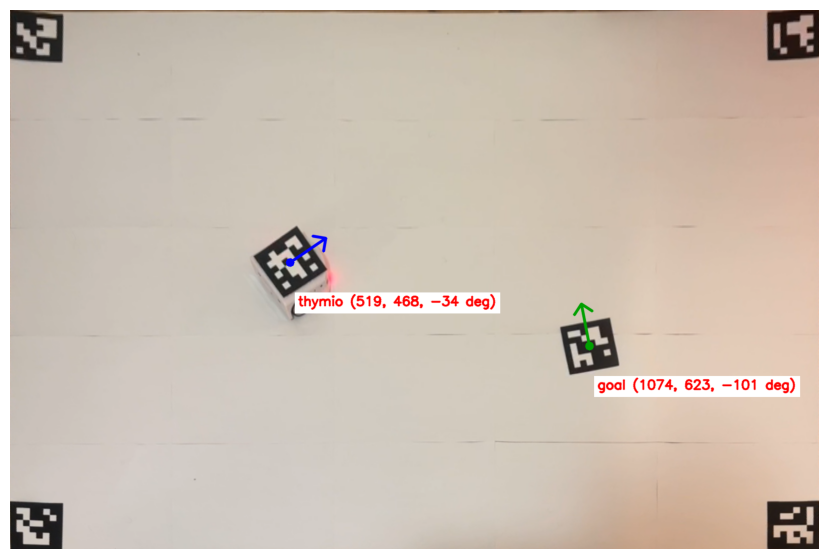

In [9]:
import computer_vision as vision

# Open webcam and capture one image
with vision.Camera(index=1) as camera:
    image = camera.read()

# Analyse the image
frame = vision.analyse_frame(image)

# Display detected information
print("Thymio position:", frame.thymio)
print("Goal position:", frame.goal)
print("Detected ArUco markers:", sorted(frame.markers.keys()))

# Display annotated map
vision.show(vision.draw_frame(frame))

Then I made a code to compute the angle from the Thymio to the goal (Desired direction) and I computed the angle that the Thymio needs to turn to be oriented towards the goal, so to have the desired direction (Angular error).

In [ ]:
import numpy as np

x, y, theta = frame.thymio
x_goal, y_goal, _ = frame.goal

# Direction toward the goal
theta_goal = np.arctan2(y_goal - y, x_goal - x)

# Angular error normalized between -pi and pi
error = np.arctan2(
    np.sin(theta_goal - theta),
    np.cos(theta_goal - theta)
)

print(f"Desired direction: {np.degrees(theta_goal):.1f}°")
print(f"Angular error: {np.degrees(error):.1f}°")

Desired direction: 15.7°
Angular error: 49.7°


Then using a proportional controller, I computed the motor commands I would give to the left and right motors, without actually giving them to Thymio, it was just a first test.

In [11]:
# Proportional controller for heading correction
Kp = 80
speed0 = 100

correction = Kp * error

spLeft = speed0 + correction
spRight = speed0 - correction

print(f"Left motor command: {spLeft:.1f}")
print(f"Right motor command: {spRight:.1f}")

Left motor command: 169.4
Right motor command: 30.6


Then, while still not making the Thymio move, I combined the two previous codes to see if I could put together the compuatation of where the Thymio needs to go and what it needs to do to go towards that goal.

In [12]:
import cv2
import numpy as np

Kp = 80
speed0 = 100
previous_transform = None

with vision.Camera(index=1, backend=cv2.CAP_DSHOW) as camera:
    try:
        while True:
            image = camera.read()

            frame = vision.analyse_frame(
                image,
                previous_transform=previous_transform,
                find_obstacles=False
            )
            previous_transform = frame.transform

            if frame.thymio is not None and frame.goal is not None:
                x, y, theta = frame.thymio
                x_goal, y_goal, _ = frame.goal

                theta_goal = np.arctan2(y_goal - y, x_goal - x)

                error = np.arctan2(
                    np.sin(theta_goal - theta),
                    np.cos(theta_goal - theta)
                )

                correction = Kp * error

                spLeft = speed0 + correction
                spRight = speed0 - correction

                print(
                    f"\rError: {np.degrees(error):.1f}° | "
                    f"Left: {spLeft:.1f} | "
                    f"Right: {spRight:.1f}",
                    end=""
                )

            display_image = vision.draw_frame(frame)
            display_image = cv2.resize(display_image, (900, 600))
            cv2.imshow("Live Thymio Tracking", display_image)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

    except KeyboardInterrupt:
        pass
    finally:
        cv2.destroyAllWindows()

Error: -3.7° | Left: 94.8 | Right: 105.28.2

Then I just tested that I could control the motors correctly with this code, it's just suppose to turn right.

In [15]:
import asyncio

try:
    # Short rotation to the right
    set_var(motor_left_target=100, motor_right_target=-100)

    await asyncio.sleep(1)

finally:
    # Stop both motors
    set_var(motor_left_target=0, motor_right_target=0)

Then I put everything together so that the robot actually goes towards the goal, however, I did not yet implemented at this stage the obstacle avoidance state machine, it's purely the Thymio going towards the goal.

In [21]:
import cv2
import numpy as np
import asyncio
import time

# Controller parameters
Kp = 80
speed0 = 100
max_speed = 200

angle_threshold = np.deg2rad(25)
goal_tolerance = 10  # pixels
max_duration = 60    # seconds

previous_transform = None

start_time = time.monotonic()

try:
    with vision.Camera(index=1, backend=cv2.CAP_DSHOW) as camera:

        while time.monotonic() - start_time < max_duration:

            # Capture and analyse image
            image = camera.read()

            frame = vision.analyse_frame(
                image,
                previous_transform=previous_transform,
                find_obstacles=False
            )

            previous_transform = frame.transform

            # Stop if localization is lost
            if frame.thymio is None or frame.goal is None:
                print("Localization lost - stopping")
                break

            x, y, theta = frame.thymio
            x_goal, y_goal, _ = frame.goal

            # Distance to goal (pixels)
            distance = np.hypot(x_goal - x, y_goal - y)

            # Stop when goal is reached
            if distance < goal_tolerance:
                print("Goal reached!")
                break

            # Desired heading
            theta_goal = np.arctan2(y_goal - y, x_goal - x)

            # Angular error
            error = np.arctan2(
                np.sin(theta_goal - theta),
                np.cos(theta_goal - theta)
            )

            # Proportional correction
            correction = np.clip(Kp * error, -55, 55)

            # Turn in place if heading error is large
            if abs(error) > angle_threshold:
                spLeft = correction
                spRight = -correction

            else:
                # Slow down near the goal
                forward_speed = speed0 if distance > 100 else 40

                spLeft = forward_speed + correction
                spRight = forward_speed - correction

            # Limit motor commands
            spLeft = int(np.clip(spLeft, -max_speed, max_speed))
            spRight = int(np.clip(spRight, -max_speed, max_speed))

            # Send commands to Thymio
            set_var(
                motor_left_target=spLeft,
                motor_right_target=spRight
            )

            print(
                f"\rDistance: {distance:.0f} px | "
                f"Error: {np.degrees(error):.1f}° | "
                f"L: {spLeft} | R: {spRight}   ",
                end=""
            )

            # Live visualization
            display_image = cv2.resize(
                vision.draw_frame(frame), (900, 600)
            )
            cv2.imshow("Waypoint Navigation", display_image)

            if cv2.waitKey(1) & 0xFF == ord("q"):
                break

            await asyncio.sleep(0.1)

except KeyboardInterrupt:
    print("\nInterrupted")

finally:
    # Always stop the motors
    set_var(motor_left_target=0, motor_right_target=0)
    cv2.destroyAllWindows()
    print("\nMotors stopped")

Distance: 117 px | Error: -0.1° | L: 99 | R: 100   Localization lost - stopping

Motors stopped


**Combining it with my code to avoid obstacles**

This is just a code to obtain the proximity sensors value.

In [26]:
# Read horizontal proximity sensors from Thymio
prox, = get_var("prox_horizontal")

# Display the five front sensors
print("Front proximity sensors:", prox[:5])

Front proximity sensors: [0, 0, 0, 2663, 3082]


This is a code to obtain the proximity sensors value for 3 seconds.

In [27]:
import asyncio

for i in range(30):
    prox, = get_var("prox_horizontal")
    print(prox[:5])
    await asyncio.sleep(0.1)

[0, 0, 0, 2627, 3040]
[0, 0, 0, 2620, 3038]
[0, 0, 0, 2620, 3038]
[0, 0, 0, 2617, 3034]
[0, 0, 0, 2617, 3034]
[0, 0, 0, 2611, 3031]
[0, 0, 0, 2611, 3031]
[0, 0, 0, 2612, 3027]
[0, 0, 0, 2612, 3027]
[0, 0, 0, 2612, 3033]
[0, 0, 0, 2612, 3033]
[0, 0, 0, 2612, 3033]
[0, 0, 0, 2607, 3026]
[0, 0, 0, 2607, 3026]
[0, 0, 0, 2606, 3022]
[0, 0, 0, 2606, 3022]
[0, 0, 0, 2599, 3018]
[0, 0, 0, 2599, 3018]
[0, 0, 0, 2601, 3024]
[0, 0, 0, 2601, 3024]
[0, 0, 0, 2590, 3013]
[0, 0, 0, 2590, 3013]
[0, 0, 0, 2591, 3009]
[0, 0, 0, 2591, 3009]
[0, 0, 0, 2585, 3004]
[0, 0, 0, 2585, 3004]
[0, 0, 0, 2580, 3000]
[0, 0, 0, 2580, 3000]
[0, 0, 0, 2580, 3000]
[0, 0, 0, 2579, 2993]


This is the code with everything put together.

In [ ]:
import computer_vision as vision #Partie de Jan
import cv2                       #Pour ouvrir la caméra
import numpy as np               #Pour faire les calculs d'angles, distances,...
import asyncio                   #Pour introduire une attente non bloquante dans la boucle
import time                      #Pour mesurer la durée d'exécution

# ============================================================
# 1. PARAMETERS
# ============================================================

# --- Goal tracking ---
Kp = 80                         #Gain du contrôleur proportionnel
speed0 = 90                     #Vitesse de base des roues
max_speed = 150                 #Valeur maximale autorisée pour chaque commande moteur

angle_threshold = np.deg2rad(25)    #Si le robot est mal orienté, il commence par tourner sur place
goal_tolerance = 35  # pixels       la distance entre le robot et le goal à laquelle le robot considère qu'il a atteint le goal

# --- Obstacle avoidance ---
obstThrL = 10                       #Seuil pour considérer qu'un obstacle est détecté
obstThrH = 20                       #Seuil pour considérer que l'obstace a disparu

obstSpeedGain = [6, 4, -2, -6, -8]

# --- Clearance ---
clearance_distance = 150  # pixels  la distance que le robot doit parcourir après avoir tourné pour éviter un obstacle
clearance_speed = 70      #la vitesse à laquelle  le robot part tout droit après avoir évité l'obstacle

clearance_start = None
obstacle_encountered = False

# --- State machine ---
# 0 = Goal tracking
# 1 = Obstacle avoidance
# 2 = Clearance

state = 1

# --- Safety ---
max_duration = 90  # seconds    durée pendant laquelle je fais mes tests
RUN_MOTORS = True  #sert juste à activer la commande des moteurs pour le test


# ============================================================
# 2. INITIALIZATION
# ============================================================

previous_transform = None
previous_state = -1

state_names = {
    0: "GOAL TRACKING",
    1: "OBSTACLE AVOIDANCE",
    2: "CLEARANCE"
}

start_time = time.monotonic() #Mesure le temps


# ============================================================
# 3. MAIN LOOP
# ============================================================

try:

    with vision.Camera(
        index=1,
        backend=cv2.CAP_DSHOW
    ) as camera:

        while time.monotonic() - start_time < max_duration:

            # ------------------------------------------------
            # A. COMPUTER VISION
            # ------------------------------------------------

            image = camera.read()

            frame = vision.analyse_frame(
                image,
                previous_transform=previous_transform,
                find_obstacles=False #j'ai pas activé la détection d'obstacles 2D pour mes tests
            )

            previous_transform = frame.transform

            # Stop if localization is lost
            if frame.thymio is None or frame.goal is None:
                print("\nLocalization lost!")
                break

            # Robot pose
            x, y, theta = frame.thymio

            # Goal position
            x_goal, y_goal, _ = frame.goal

            # Distance to goal
            distance = np.hypot(    #Calcule la distance entre le robot et le goal
                x_goal - x,
                y_goal - y
            )

            # Stop when goal is reached
            if distance < goal_tolerance:
                print("\nGoal reached!")
                break


            # ------------------------------------------------
            # B. PROXIMITY SENSORS
            # ------------------------------------------------

            prox, = get_var("prox_horizontal")

            # Five front sensors
            obst = prox[:5]


            # ------------------------------------------------
            # C. STATE MACHINE
            # ------------------------------------------------

            if state == 0:

                # GOAL TRACKING

                # Switch to avoidance if obstacle detected
                if any(value > obstThrH for value in obst):

                    state = 1
                    obstacle_encountered = True


            elif state == 1:

                # OBSTACLE AVOIDANCE

                # Register obstacle detection
                if any(value > obstThrH for value in obst):
                    obstacle_encountered = True

                # Check if obstacle is no longer detected
                obstacle_gone = all(
                    value < obstThrL for value in obst
                )

                if obstacle_gone:

                    if obstacle_encountered:

                        # Start clearance phase
                        state = 2

                        # Store current robot position
                        clearance_start = (x, y)

                    else:

                        # No obstacle at initialization
                        state = 0


            elif state == 2:

                # CLEARANCE

                # If an obstacle reappears, avoid it
                if any(value > obstThrH for value in obst):

                    state = 1

                else:

                    # Distance traveled since clearance started
                    distance_cleared = np.hypot(
                        x - clearance_start[0],
                        y - clearance_start[1]
                    )

                    # Resume goal tracking after clearance
                    if distance_cleared >= clearance_distance:

                        state = 0
                        obstacle_encountered = False
                        clearance_start = None


            # ------------------------------------------------
            # D. MOTOR COMMANDS
            # ------------------------------------------------

            if state == 0:

                # ============================================
                # GOAL TRACKING
                # ============================================

                # Desired heading
                theta_goal = np.arctan2(
                    y_goal - y,
                    x_goal - x
                )

                # Angular error normalized to [-pi, pi]
                error = np.arctan2(
                    np.sin(theta_goal - theta),
                    np.cos(theta_goal - theta)
                )

                # Proportional controller
                correction = np.clip(
                    Kp * error,
                    -55,
                    55
                )

                # Turn in place if heading error is large
                if abs(error) > angle_threshold:

                    spLeft = correction
                    spRight = -correction

                else:

                    # Reduce speed near goal
                    forward_speed = (
                        speed0 if distance > 100 else 40
                    )

                    spLeft = forward_speed + correction
                    spRight = forward_speed - correction


            elif state == 1:

                # ============================================
                # OBSTACLE AVOIDANCE
                # ============================================

                spLeft = speed0
                spRight = speed0

                for i in range(5):

                    spLeft += (
                        obst[i] * obstSpeedGain[i] // 100
                    )

                    spRight += (
                        obst[i] * obstSpeedGain[4 - i] // 100
                    )


            elif state == 2:

                # ============================================
                # CLEARANCE
                # ============================================

                # Move straight ahead before returning
                # to goal tracking

                spLeft = clearance_speed
                spRight = clearance_speed


            # ------------------------------------------------
            # E. MOTOR LIMITS
            # ------------------------------------------------

            spLeft = int(np.clip(
                spLeft,
                -max_speed,
                max_speed
            ))

            spRight = int(np.clip(
                spRight,
                -max_speed,
                max_speed
            ))


            # ------------------------------------------------
            # F. SEND COMMANDS TO THYMIO
            # ------------------------------------------------

            if RUN_MOTORS:

                set_var(
                    motor_left_target=spLeft,
                    motor_right_target=spRight
                )


            # ------------------------------------------------
            # G. MONITORING
            # ------------------------------------------------

            # Display state transitions
            if state != previous_state:

                print(
                    f"\nState changed to {state}: "
                    f"{state_names[state]}"
                )

                previous_state = state


            # Display robot information
            print(
                f"\rState: {state} | "
                f"Distance: {distance:.0f} px | "
                f"Left: {spLeft} | "
                f"Right: {spRight} | "
                f"Prox: {obst}   ",
                end=""
            )


            # ------------------------------------------------
            # H. LIVE VISUALIZATION
            # ------------------------------------------------

            display_image = vision.draw_frame(frame)

            display_image = cv2.resize(
                display_image,
                (900, 600)
            )

            cv2.imshow(
                "Local Navigation",
                display_image
            )

            # Press Q to stop
            if cv2.waitKey(1) & 0xFF == ord("q"):
                print("\nStopped by user")
                break

            # Control loop delay
            await asyncio.sleep(0.1)


except KeyboardInterrupt:

    print("\nInterrupted by user")


finally:

    # Always attempt to stop the motors
    set_var(
        motor_left_target=0,
        motor_right_target=0
    )

    cv2.destroyAllWindows()

    print("\nMotors stopped")


State changed to 0: GOAL TRACKING
State: 0 | Distance: 409 px | Left: 89 | Right: 90 | Prox: [0, 0, 0, 0, 0]   
State changed to 1: OBSTACLE AVOIDANCE
State: 1 | Distance: 369 px | Left: -131 | Right: 150 | Prox: [0, 0, 0, 0, 2756]      
State changed to 2: CLEARANCE
State: 2 | Distance: 370 px | Left: 70 | Right: 70 | Prox: [0, 0, 0, 0, 0]   
State changed to 0: GOAL TRACKING
State: 0 | Distance: 122 px | Left: 89 | Right: 90 | Prox: [0, 0, 0, 0, 0]    
Localization lost!

Motors stopped


Exception in thread Thread-3:
Traceback (most recent call last):
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\threading.py", line 1041, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\site-packages\tdmclient\tcp.py", line 73, in run
    packet = self.read_packet()
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\site-packages\tdmclient\tcp.py", line 66, in read_packet
    raise error
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\site-packages\tdmclient\tcp.py", line 59, in read_packet
    packet_len = self.read_uint32()
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\site-packages\tdmclient\tcp.py", line 46, in read_uint32
    b = self.io.read(4)
  File "c:\Users\lucsk\AppData\Local\Programs\Python\Python313\Lib\site-packages\tdmclient\tcp.py", line 99, in read
    return self.socket.recv(n)
           ~~~~~~~~~~~~~~~~^^^
ConnectionResetEr

It is still not yet perfect, but the logic behind the state machine is working.